<div style="background-color: steelblue; padding: 10px; border-radius: 5px;">
    <p style="margin: 10;"></p>
    <h1 style="text-align: center; margin: 0; font-weight: bold; color: white;">SWOT OMIP : Region Domain</h1>
    <p style="margin: 10;"></p>
</div>


## 📦**Imports** 

In [13]:
%%time

##################################
#Imports

from datetime import datetime
import s3fs
import xarray as xr
import pyinterp
from widetrax import DataPreprocessing as dp
from widetrax import Spectra as sp
import numpy as np
import json
from watermark import watermark
import time
import platform
from shapely.geometry import shape, box

import matplotlib.pyplot as plt
import cartopy.crs as ccrs
import cartopy.feature as cfeature
import numpy as np
#from widetrax import Spectra as sp
import plot_psd1Xglobal1 as pp2X
import importlib

importlib.reload(pp2X)

import position_function as pf
importlib.reload(pf)

import Spectra as sp1


CPU times: user 2.04 ms, sys: 3.17 ms, total: 5.21 ms
Wall time: 29.5 ms


## **Defining functions**



In [14]:
# This function read the spectra json file from local because geomar is private (for now?). 
def read_json_local(folder,file):
        with open(file, mode='rb') as fileObj:
            data = json.load(fileObj)
        return data

In [15]:


def plot_boxspectrum(fig,region_boxes,models,modellabel, cds,selected,region_name,north_boxes,south_boxes,colors,lsts,box_legend=0):

    #MODEL LOAD

    max_horizontal_gridsize = [0,0,0] #,2.224,2.224,25,7,0]

    ax = fig.add_axes([0.15, 0.53, 0.7, 0.45],projection=ccrs.PlateCarree())
    ax.set_extent([cds[0]-2,cds[1]+2,cds[2]-2,cds[3]+2], crs=ccrs.PlateCarree())
    gl = ax.gridlines(
        crs=ccrs.PlateCarree(),
        draw_labels=True,
        linewidth=2,
            color='gray',
        alpha=0.5,
        linestyle='--'
    )

    # Optional: clean up label placement
    gl.top_labels = False
    gl.right_labels = False
    gl.xlabel_style = {'size': 10}
    gl.ylabel_style = {'size': 10}
    gl.xlines = False
    gl.ylines = False
    ax.set_title(region_name,fontsize=15, fontweight="bold", color="black")
    ax.add_feature(cfeature.LAND,zorder=10, facecolor="lightgray")
    ax.add_feature(cfeature.COASTLINE)

    ibox=0
    for ir in region_boxes:
        box=region_boxes[ibox]
        poly=selected[ir]

        # Size of inset (tune this)

        # Box center
        lon_min, lat_min, lon_max, lat_max = poly.bounds
        lon_c = 0.5 * (lon_min + lon_max)-2
        lat_c = 0.5 * (lat_min + lat_max)-2

        # Convert lon/lat → figure coordinates
        x_fig, y_fig = ax.transData.transform(
            ccrs.PlateCarree().transform_point(lon_c, lat_c, ccrs.PlateCarree())
            )
        x_fig, y_fig = fig.transFigure.inverted().transform((x_fig, y_fig))
        w, h = 0.08, 0.08

               
        wlmin=50
        wlmax=600
        inset_ax = fig.add_axes([x_fig , y_fig , w, h])
        season1="JFM"
        Ra=[]
        freqJFM=[]
        season2="JAS"
        freqJAS=[]
        # Plot spectrum
        for imod in models :
            folder="GLOBALv2/"
            if imod !="GEOMAR":
                # Load season 1
                filename = folder+ imod +"/Global_box_" + str(box) + "_" + season1 + "_" + imod + ".json"
                data=read_json_local(folder,filename)
                freqJFM0=np.array(data["Frequency"])
                spectrumJFM0=np.array(data["Spectra"])
                wavelength=1/np.array(freqJFM0)
                poswl=np.where((wavelength>wlmin) & (wavelength<wlmax))
                freqJFM.append(freqJFM0[poswl[0]])

                # Load season 2
                filename = folder+ imod +"/Global_box_" + str(box) + "_" + season2 + "_" + imod + ".json"
                data=read_json_local(folder,filename)
                freqJAS0=np.array(data["Frequency"])
                spectrumJAS0=np.array(data["Spectra"])
                wavelength=1/np.array(freqJAS0)
                poswl=np.where((wavelength>wlmin) & (wavelength<wlmax))
                freqJAS.append(freqJAS0[poswl[0]])

                if box in north_boxes:
                    Ra.append(spectrumJFM0[poswl[0]]/spectrumJAS0[poswl[0]])
                elif box in south_boxes:
                    Ra.append(spectrumJAS0[poswl[0]]/spectrumJFM0[poswl[0]])
            elif imod == "GEOMAR":
                kyr=0
                for yr in range(2021,2024):
                    filename = folder+ imod+ "/" + str(yr) +"/Global_box_" + str(box) + "_" + season1 + "_" + imod + ".json"
                    data=read_json_local(folder,filename)
                    freqJFM0=np.array(data["Frequency"])
                    spectrumJFM0=np.array(data["Spectra"])
                    wavelength=1/np.array(freqJFM0)
                    poswl=np.where((wavelength>wlmin) & (wavelength<wlmax))
                    filename = folder+ imod +"/Global_box_" + str(box) + "_" + season2 + "_" + imod + ".json"
                    data=read_json_local(folder,filename)
                    freqJAS0=np.array(data["Frequency"])
                    poswl=np.where((wavelength>wlmin) & (wavelength<wlmax))
                    spectrumJAS0=np.array(data["Spectra"])
                    if yr==2021:
                        spectrumJFM1=np.zeros((len(spectrumJFM0)))
                        spectrumJAS1=np.zeros((len(spectrumJAS0)))
                    spectrumJFM1=spectrumJFM1+spectrumJFM0
                    spectrumJAS1=spectrumJAS1+spectrumJAS0
                    kyr=kyr+1
                freqJFM.append(freqJFM0[poswl[0]])
                freqJAS.append(freqJAS0[poswl[0]])
                if box in north_boxes:
                    Ra.append((spectrumJFM0[poswl[0]]/kyr)/(spectrumJAS0[poswl[0]]/kyr))
                elif box in south_boxes:
                    Ra.append((spectrumJAS0[poswl[0]]/kyr)/(spectrumJFM0[poswl[0]]/kyr))


       
        if ibox==box_legend:
               pp2X.plot_psd(inset_ax, np.squeeze(np.array(freqJAS)).T,  psds = Ra , unit = "m2",psd_labels=modellabel,
                     legend=True,bba_leg=(4.5,2),colors=colors,lsts=lsts,xtick_show=True, ytick_show=True,xlabel_upper=False,xlabel_lower=False,
                             wavelength_ticks = np.array([50,250,100,500]),
                     ylabel=False,savefig=True, filename=("globa_" + season1 + ".png"),plot_transparent=False,slope=False,
                            scaleX='log', scaleY='log')
            

        else:
                pp2X.plot_psd(inset_ax, np.squeeze(np.array(freqJAS)).T, psds = Ra, unit = "m2",psd_labels=modellabel,
                      legend=False,colors=colors,lsts=lsts,xtick_show=True, ytick_show=True,xlabel_upper=False,xlabel_lower=False,
                               wavelength_ticks = np.array([50,250,100,500]),
                      ylabel=False,savefig=True, filename=("globa_" + season1 + ".png"),plot_transparent=False,slope=False,
                             scaleX='log', scaleY='log')
        #del freq, spectrum
        ibox=ibox+1
        plt.axhline(y=1, color='gray', linestyle='--')
        inset_ax.set_ylim([1e-1,1e1])
        #inset_ax.set_xlim([50,500])
    ax.set_extent([cds[0]-2,cds[1]+2,cds[2]-2,cds[3]+2], crs=ccrs.PlateCarree())
    #ax.legend(models,loc='upper right', bbox_to_anchor=(1, 1))

    return 

In [16]:
def load_spectrum(folder,region_boxes,models,season1,season2,Wl):
    box=0
    psdsW=np.zeros((len(region_boxes),len(models)))
    psdsS=np.zeros((len(region_boxes),len(models)))


    FbS=np.zeros((len(Wl),len(models))) #Mean spectrum over the region in summer
    FbW=np.zeros((len(Wl),len(models))) #Mean spectrum over the region in winter
    aFbS=np.zeros((3,len(Wl)))
    aFbW=np.zeros((3,len(Wl)))

    km=0
    for imod in models:
        ki=0
        for i in (region_boxes):

            if (i!=14) and (i!=15):
                season=season1
                spectrumJFM=[]
                freqJFM=[]
                # Plot spectrum JFM
                if imod !="GEOMAR":
                    filename = folder+ imod +"/Global_box_" + str(i) + "_" + season + "_" + imod + ".json"
                    data=read_json_local(folder,filename)
                    spectrumJFM.append(data["Spectra"])
                    freqJFM.append(data["Frequency"])
                    FbW[:,km]=FbW[:,km]+np.interp(1/Wl,np.array(data["Frequency"]), np.array(data["Spectra"]))
                elif imod == "GEOMAR":
                    kyr=0
                    for yr in range(2021,2024):
                        spectrumJFM=[]
                        freqJFM=[]
                        filename = folder+ imod+ "/" + str(yr) +"/Global_box_" + str(i) + "_" + season + "_" + imod + ".json"
                        data=read_json_local(folder,filename)
                        spectrumJFM.append(data["Spectra"])
                        freqJFM.append(data["Frequency"])
                        aFbW[kyr,:]=aFbW[kyr,:]+np.interp(1/Wl,np.array(data["Frequency"]), np.array(data["Spectra"]))
                        kyr=kyr+1
                    FbW[:,km]=np.nanmean(aFbW,axis=0)
                    FbWy=np.nanstd(aFbW,axis=0)

                season=season2
                spectrumJAS=[]
                freqJAS=[]
                # Plot spectrum JAS
                if imod !="GEOMAR":
                    filename = folder+ imod +"/Global_box_" + str(i) + "_" + season + "_" + imod + ".json"
                    data=read_json_local(folder,filename)
                    spectrumJAS.append(data["Spectra"])
                    freqJAS.append(data["Frequency"])
                    FbS[:,km]=FbS[:,km]+np.interp(1/Wl,np.array(data["Frequency"]), np.array(data["Spectra"]))
                elif imod == "GEOMAR":
                    kyr=0
                    for yr in range(2021,2024):
                        spectrumJAS=[]
                        freqJAS=[]
                        filename = folder+ imod+ "/" + str(yr) +"/Global_box_" + str(i) + "_" + season + "_" + imod + ".json"
                        data=read_json_local(folder,filename)
                        spectrumJAS.append(data["Spectra"])
                        freqJAS.append(data["Frequency"])
                        aFbS[kyr,:]=aFbS[kyr,:]+np.interp(1/Wl,np.array(data["Frequency"]), np.array(data["Spectra"]))
                        kyr=kyr+1
                    FbS[:,km]=np.nanmean(aFbS,axis=0)
                ki=ki+1
        km=km+1

    FbS=FbS/len(region_boxes)
    FbW=FbW/len(region_boxes)
    aFbW=aFbW/len(region_boxes)
    aFbS=aFbS/len(region_boxes)
    return FbS, FbW,aFbS, aFbW


In [17]:

# Finding north and south position boxes
boxesjson="mostly_ocean_boxes_filtered.geojson"
north_boxes, south_boxes=pf.position_boxes_northsouth(boxesjson)

North boxes: 93
South boxes: 189


## **Configuration options**

/var/folders/c9/n_765b212hs2ss0sxlp635dr0000gp/T/ipykernel_9909/2705418603.py:66: RuntimeWarning: divide by zero encountered in divide
  wavelength=1/np.array(freqJFM0)
/var/folders/c9/n_765b212hs2ss0sxlp635dr0000gp/T/ipykernel_9909/2705418603.py:75: RuntimeWarning: divide by zero encountered in divide
  wavelength=1/np.array(freqJAS0)
/var/folders/c9/n_765b212hs2ss0sxlp635dr0000gp/T/ipykernel_9909/2705418603.py:90: RuntimeWarning: divide by zero encountered in divide
  wavelength=1/np.array(freqJFM0)
/var/folders/c9/n_765b212hs2ss0sxlp635dr0000gp/T/ipykernel_9909/2705418603.py:66: RuntimeWarning: divide by zero encountered in divide
  wavelength=1/np.array(freqJFM0)
/var/folders/c9/n_765b212hs2ss0sxlp635dr0000gp/T/ipykernel_9909/2705418603.py:75: RuntimeWarning: divide by zero encountered in divide
  wavelength=1/np.array(freqJAS0)
/var/folders/c9/n_765b212hs2ss0sxlp635dr0000gp/T/ipykernel_9909/2705418603.py:90: RuntimeWarning: divide by zero encountered in divide
  wavelength=1/np.ar

(0.3, 3.0)

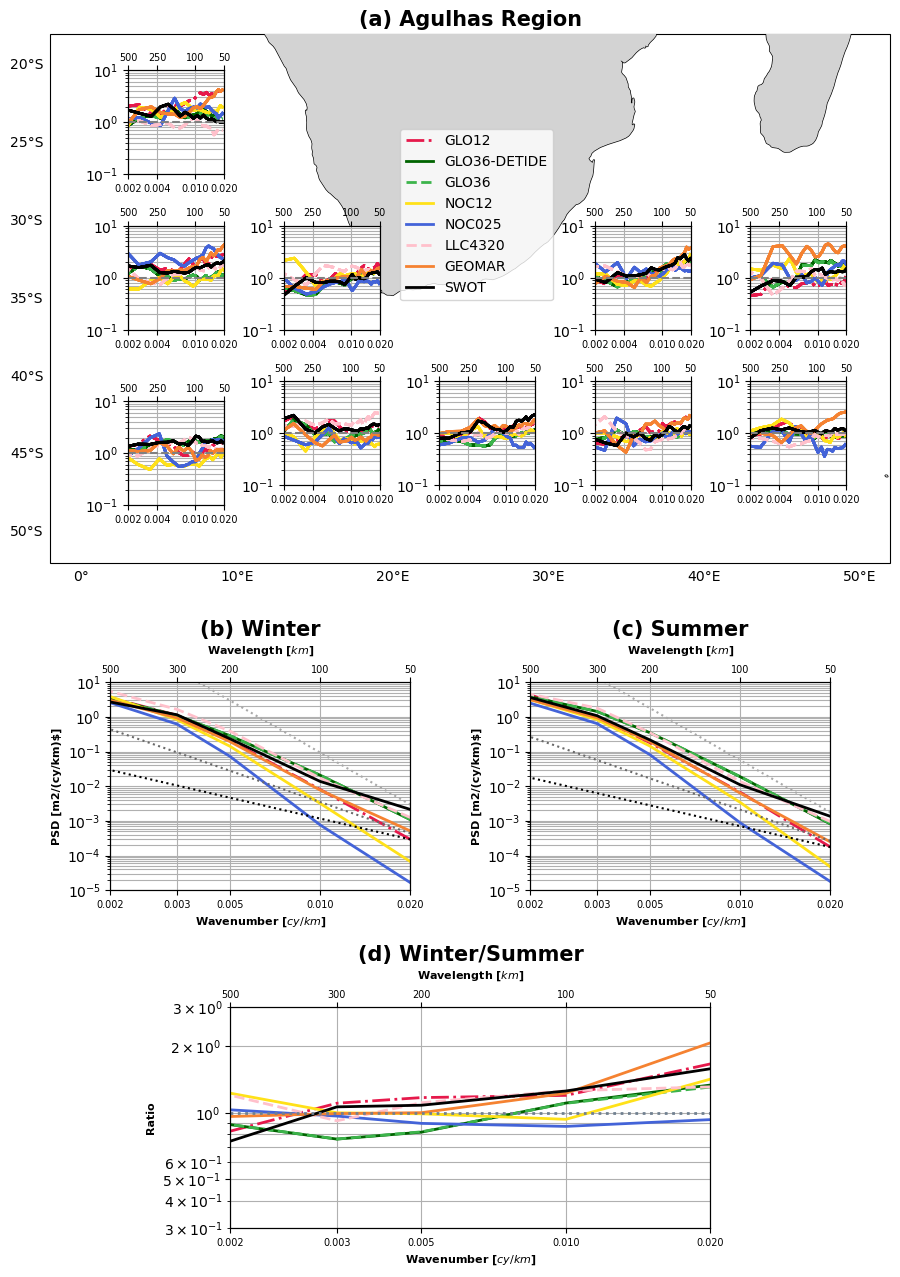

In [18]:
# -----------------------------
# Define variables
# -----------------------------
models=["GLO12V4","GLO36V1NOTIDE","GLO36V1","NOC12","NOC025","LLC4320","GEOMAR","SWOT"] #["GLO12","GLO36","NOC12","NOC025","SWOT"]
modellabel=["GLO12","GLO36-DETIDE","GLO36","NOC12","NOC025","LLC4320","GEOMAR","SWOT"] #["GLO12","GLO36","NOC12","NOC025","SWOT"]

folder="GLOBALv2/"
lst=['dashdot','solid','dashed','solid','solid','dashed','solid','solid']

colors = [
        "#E6194B",  # red
        "darkgreen",
        "#3CB44B",  # green
        "#FFE119",  # yellow
        "#4363D8",  # blue
        "pink",  # purple
        "#F58231",
        "k"]        #"#F58231",  # orange
        #

regcoordA=[0,50, -50, -20] # Domain lon_min,lon_max, lat_min, lat_max
# -----------------------------
# End Definition
# -----------------------------
selected, region_boxesA=pf.position_boxes(boxesjson,regcoord=regcoordA) # Index boxes for global ocean, and the region
region_boxes=region_boxesA
cds=regcoordA
fig = plt.figure(figsize=(12, 13))
plot_boxspectrum(fig,region_boxes, models,modellabel,cds,selected,'(a) Agulhas Region',north_boxes,south_boxes,colors,lst, box_legend=5)
Wl=np.array([50,100,200,300,500])


FbS_A, FbW_A,FbS_Ay, FbW_Ay=load_spectrum(folder,region_boxesA,models,'JFM','JAS',Wl) # FbS =JAS; FbW=JFM

ax1 = fig.add_axes([0.2, 0.3, 0.25, 0.16])
pp2X.plot_psd(ax1, 1/Wl, FbS_A.T, unit = "m2",psd_labels=modellabel,title="(b) Winter",
             savefig=False,plot_transparent=False,legend=False,colors=colors,lsts=lst,
             wavelength_ticks = Wl,xlabel_upper=True,xlabel_lower=True)
ax1.set_ylim([1e-5,1e1])
ax2 = fig.add_axes([0.55, 0.3, 0.25, 0.16])
pp2X.plot_psd(ax2, 1/Wl, FbW_A.T, unit = "m2",psd_labels=modellabel,title="(c) Summer",
             savefig=False,plot_transparent=False,legend=False,colors=colors,lsts=lst,
             wavelength_ticks = Wl,xlabel_upper=True,xlabel_lower=True)
ax2.set_ylim([1e-5,1e1])

Ra_A=FbS_A/FbW_A
ax3 = fig.add_axes([0.3, 0.04, 0.4, 0.17])
pp2X.plot_psd(ax3, 1/Wl, Ra_A.T, unit = "m2",psd_labels=modellabel,
              title="(d) Winter/Summer",wavelength_ticks = np.array(Wl),savefig=False,plot_transparent=False,slope=False,
              legend=None,colors=colors,ylabelname="Ratio",lsts=lst,xlabel_upper=True,xlabel_lower=True)
ax3.set_yticks([0.2, 0.5, 1, 2, 5])
ax3.set_yticklabels([
    r'$2\times10^{-1}$',
    r'$5\times10^{-1}$',
    r'$10^{0}$',
    r'$2\times10^{0}$',
    r'$5\times10^{0}$'
])
ax3.axhline(y=1, linestyle='dotted', linewidth=2,color="slategrey")
ax3.set_ylim([0.3,3])

#plt.savefig("FigV2/agulhas_modelsswot_detided.png",dpi=300,transparent=False)


/var/folders/c9/n_765b212hs2ss0sxlp635dr0000gp/T/ipykernel_9909/2705418603.py:66: RuntimeWarning: divide by zero encountered in divide
  wavelength=1/np.array(freqJFM0)
/var/folders/c9/n_765b212hs2ss0sxlp635dr0000gp/T/ipykernel_9909/2705418603.py:75: RuntimeWarning: divide by zero encountered in divide
  wavelength=1/np.array(freqJAS0)
/var/folders/c9/n_765b212hs2ss0sxlp635dr0000gp/T/ipykernel_9909/2705418603.py:90: RuntimeWarning: divide by zero encountered in divide
  wavelength=1/np.array(freqJFM0)
/var/folders/c9/n_765b212hs2ss0sxlp635dr0000gp/T/ipykernel_9909/2705418603.py:66: RuntimeWarning: divide by zero encountered in divide
  wavelength=1/np.array(freqJFM0)
/var/folders/c9/n_765b212hs2ss0sxlp635dr0000gp/T/ipykernel_9909/2705418603.py:75: RuntimeWarning: divide by zero encountered in divide
  wavelength=1/np.array(freqJAS0)
/var/folders/c9/n_765b212hs2ss0sxlp635dr0000gp/T/ipykernel_9909/2705418603.py:90: RuntimeWarning: divide by zero encountered in divide
  wavelength=1/np.ar

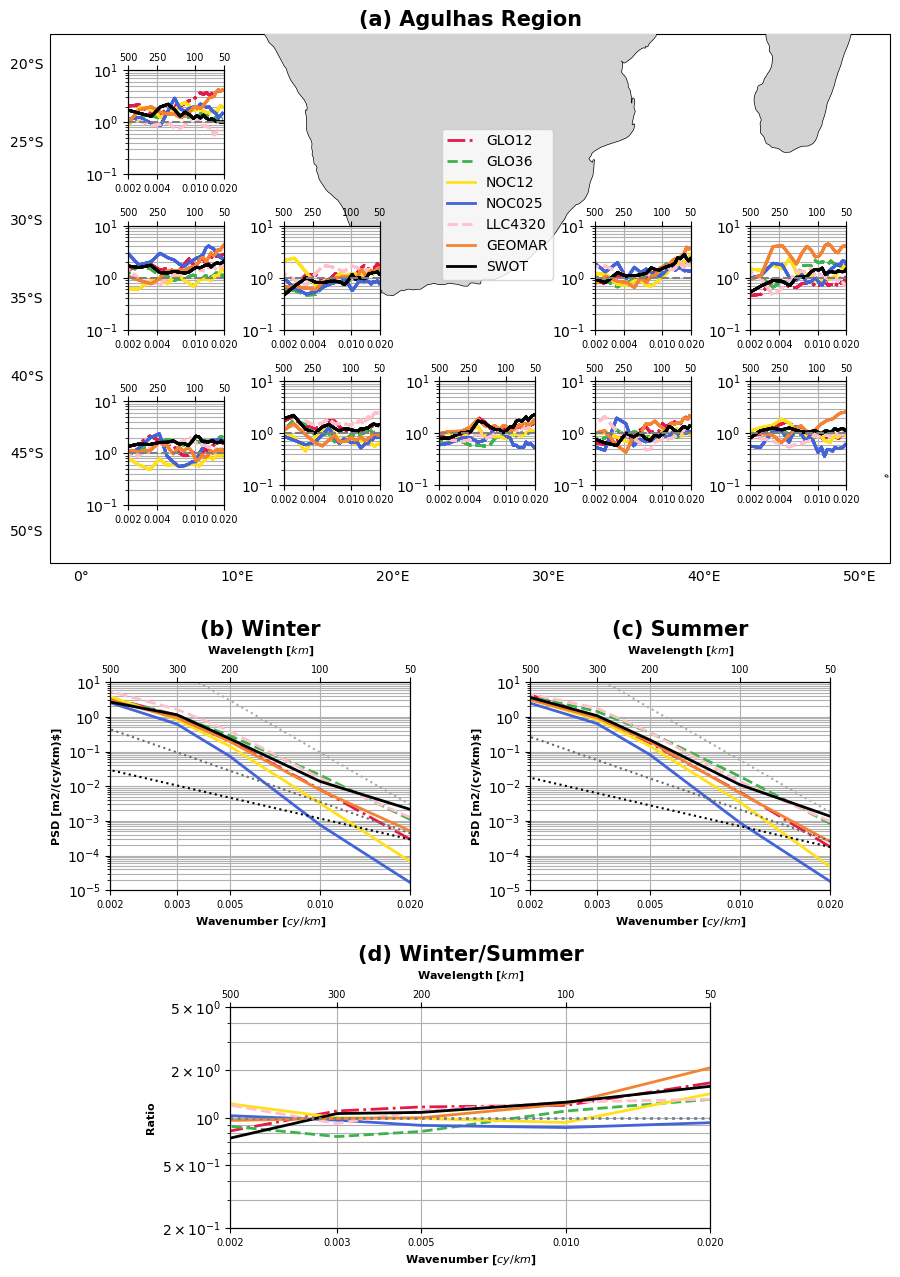

In [19]:
# -----------------------------
# Define variables
# -----------------------------
models=["GLO12V4","GLO36V1","NOC12","NOC025","LLC4320","GEOMAR","SWOT"] #["GLO12","GLO36","NOC12","NOC025","SWOT"]
modellabel=["GLO12","GLO36","NOC12","NOC025","LLC4320","GEOMAR","SWOT"] #["GLO12","GLO36","NOC12","NOC025","SWOT"]

folder="GLOBALv2/"
lst=['dashdot','dashed','solid','solid','dashed','solid','solid']

colors = [
        "#E6194B",  # red
        "#3CB44B",  # green
        "#FFE119",  # yellow
        "#4363D8",  # blue
        "pink",  # purple
        "#F58231",
        "k"]        #"#F58231",  # orange
        #
regcoordA=[0,50, -50, -20] # Domain lon_min,lon_max, lat_min, lat_max

# -----------------------------
# END DEFINITION
# -----------------------------
selected, region_boxesA=pf.position_boxes(boxesjson,regcoord=regcoordA) # Index boxes for global ocean, and the region
region_boxes=region_boxesA
cds=regcoordA
fig = plt.figure(figsize=(12, 13))
plot_boxspectrum(fig,region_boxes, models,modellabel,cds,selected,'(a) Agulhas Region',north_boxes,south_boxes,colors,lst, box_legend=5)
Wl=np.array([50,100,200,300,500])

# WINTER
FbS_A, FbW_A,FbS_Ay, FbW_Ay=load_spectrum(folder,region_boxesA,models,'JFM','JAS',Wl) # FbS =JAS; FbW=JFM

ax1 = fig.add_axes([0.2, 0.3, 0.25, 0.16])
pp2X.plot_psd(ax1, 1/Wl, FbS_A.T, unit = "m2",psd_labels=modellabel,title="(b) Winter",
             savefig=False,plot_transparent=False,legend=False,colors=colors,lsts=lst,
             wavelength_ticks = Wl,xlabel_upper=True,xlabel_lower=True)
ax1.set_ylim([1e-5,1e1])
ax2 = fig.add_axes([0.55, 0.3, 0.25, 0.16])
pp2X.plot_psd(ax2, 1/Wl, FbW_A.T, unit = "m2",psd_labels=modellabel,title="(c) Summer",
             savefig=False,plot_transparent=False,legend=False,colors=colors,lsts=lst,
             wavelength_ticks = Wl,xlabel_upper=True,xlabel_lower=True)
ax2.set_ylim([1e-5,1e1])

Ra_A=FbS_A/FbW_A
ax3 = fig.add_axes([0.3, 0.04, 0.4, 0.17])
pp2X.plot_psd(ax3, 1/Wl, Ra_A.T, unit = "m2",psd_labels=modellabel,
              title="(d) Winter/Summer",wavelength_ticks = np.array(Wl),savefig=False,plot_transparent=False,slope=False,
              legend=None,colors=colors,ylabelname="Ratio",lsts=lst,xlabel_upper=True,xlabel_lower=True)
ax3.set_ylim([1e-1*2,1e1/2])
ax3.set_yticks([0.2, 0.5, 1, 2, 5])
ax3.set_yticklabels([
    r'$2\times10^{-1}$',
    r'$5\times10^{-1}$',
    r'$10^{0}$',
    r'$2\times10^{0}$',
    r'$5\times10^{0}$'
])
ax3.axhline(y=1, linestyle='dotted', linewidth=2,color="slategrey")
plt.savefig("FigV2/agulhas_modelsswot.png",dpi=300,transparent=False)


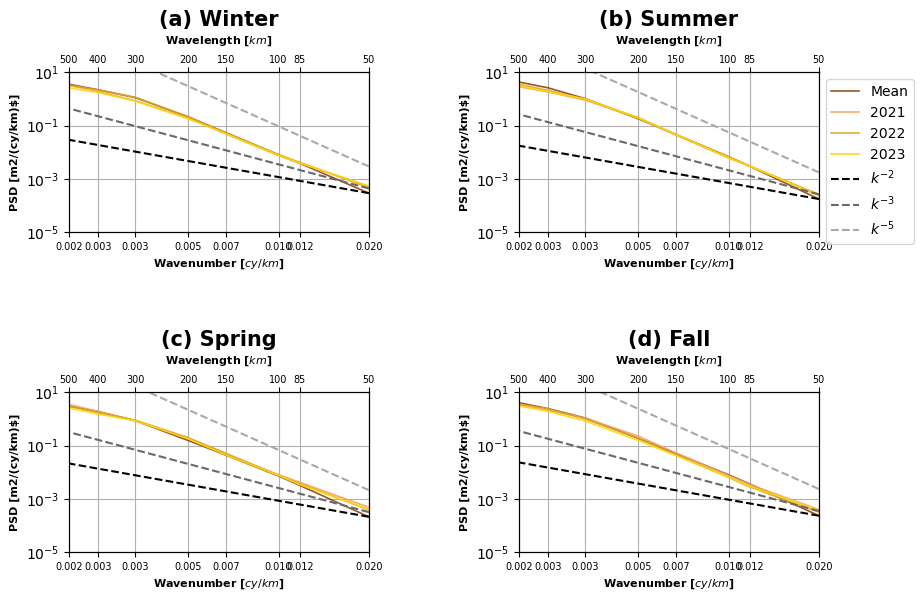

In [28]:
#Wl=np.array([500,400,300,250,200,150,125,100,85,60,50])
Wl=np.array([50,85,100,150,200,300,400,500])

# Defining region: AGULHAS CURRENT
regcoordA=[0,50, -50, -20] # Domain lon_min,lon_max, lat_min, lat_max
selected, region_boxesA=pf.position_boxes(boxesjson,regcoord=regcoordA) # Index boxes for global ocean, and the region
FbS_A, FbW_A,FbS_Ayr, FbW_Ayr=load_spectrum(folder,region_boxesA,models,'JFM','JAS',Wl) # FbS =JAS; FbW=JFM
FbF_A, FbSp_A,FbF_Ayr, FbSp_Ayr=load_spectrum(folder,region_boxesA,models,'AMJ','OND',Wl) # FbS =JAS; FbW=JFM

fig = plt.figure(figsize=(10, 8))
ax1 = fig.add_axes([0.1, 0.6, 0.3, 0.2])
pp2X.plot_psd(ax1, 1/Wl, [FbS_A[:,0],FbS_Ayr[0,:],FbS_Ayr[1,:],FbS_Ayr[2,:]], unit = "m2",psd_labels=["Mean","2021","2022","2023"],title="(a) Winter",
             savefig=False,plot_transparent=False,legend=False,colors=['saddlebrown','sandybrown','goldenrod','gold'],wavelength_ticks = Wl)
ax1.set_ylim([1e-5,1e1])
ax2 = fig.add_axes([0.55, 0.6, 0.3, 0.2])
pp2X.plot_psd(ax2, 1/Wl, [FbW_A[:,0],FbW_Ayr[0,:],FbW_Ayr[1,:],FbW_Ayr[2,:]], unit = "m2",psd_labels=["Mean","2021","2022","2023"],title="(b) Summer",
             savefig=False,plot_transparent=False,legend=True,colors=['saddlebrown','sandybrown','goldenrod','gold'],wavelength_ticks = Wl)
ax2.set_ylim([1e-5,1e1])
ax3 = fig.add_axes([0.1, 0.2, 0.3, 0.2])
pp2X.plot_psd(ax3, 1/Wl, [FbF_A[:,0],FbF_Ayr[0,:],FbF_Ayr[1,:],FbF_Ayr[2,:]], unit = "m2",psd_labels=["Mean","2021","2022","2023"],title="(c) Spring",
             savefig=False,plot_transparent=False,legend=False,colors=['saddlebrown','sandybrown','goldenrod','gold'],wavelength_ticks = Wl)
ax3.set_ylim([1e-5,1e1])
ax4 = fig.add_axes([0.55, 0.2, 0.3, 0.2])
pp2X.plot_psd(ax4, 1/Wl, [FbSp_A[:,0],FbSp_Ayr[0,:],FbSp_Ayr[1,:],FbSp_Ayr[2,:]], unit = "m2",psd_labels=["Mean","2021","2022","2023"],title="(d) Fall",
             savefig=False,plot_transparent=False,legend=False,colors=['saddlebrown','sandybrown','goldenrod','gold'],
              wavelength_ticks = Wl)
ax4.set_ylim([1e-5,1e1])

plt.savefig("FigV2/agulhas_spectrum_geomarperyear.png",dpi=300,transparent=False)
